# Implementing a Recommendation System with Deep Learning and PyTorch

This notebook looks into the process of implementing and training a simple embeddings-based collaborative filtering recommendation system using PyTorch, Pandas, and Scikit-Learn.

Collaborative Filtering: Predict the reaction of a user on a specific item based on reactions of "similar" users where the "similarity" id calculated using the ratings or reviews left by these users

We will build a table with rows (users) and columns (ratings). THen we will use a training algorithm to infer similariteies between users rating patterns to "fill the gaps" to predicts ratings that are missing.

# Preparing the tools

In [1]:
import os
import time
import math
import copy
import pickle
import webbrowser
import zipfile
from pathlib import Path
from itertools import zip_longest
from urllib.error import URLError
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

import torch
import torch.nn as nn
from torch import optim
from torch.optim.lr_scheduler import _LRScheduler
from torch.utils.data import DataLoader

# Load data

### Define paths

In [2]:
dataset = "https://files.grouplens.org/datasets/movielens/ml-1m.zip"
download_path = "/Users/vabarca/Downloads"
working_path = "./"

### Download and extract zip file

In [3]:
def download_dataset(link, download_path, working_path):
    webbrowser.open(link)
    time.sleep(5)

    file_name = link.split("/")[-1]
    final_path = os.path.join(download_path, file_name)
    if not os.path.exists(final_path):
        print("File was not downloaded")
        return

    with zipfile.ZipFile(final_path) as file:
        file.extractall(working_path)

    return os.path.join(working_path, file_name.replace(".zip", ""))

In [4]:
data_path = download_dataset(dataset, download_path, working_path)

### Load Data

In [5]:
def load_data(path):
    path = Path(path)
    files = {}
    for filename in path.glob("*"):
        if filename.suffix == ".csv":
            files[filename.stem] = pd.read_csv(filename)
        elif filename.suffix == ".dat":
            if filename.stem == "ratings":
                columns = ["UserID", "MovieID", "Rating", "Timestamp"]
            else:
                columns = ["MovieID", "Title", "Genres"]
            data = pd.read_csv(filename, sep="::", names=columns, encoding="latin-1")
            files[filename.stem] = data
    return files["ratings"], files["movies"]

In [6]:
ratings, movies = load_data(os.path.join(data_path))

/var/folders/z1/xrwht_kd0r54n8qj8_jdt1080000gn/T/ipykernel_34317/2131886634.py:12: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  data = pd.read_csv(filename, sep="::", names=columns, encoding="latin-1")
/var/folders/z1/xrwht_kd0r54n8qj8_jdt1080000gn/T/ipykernel_34317/2131886634.py:12: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  data = pd.read_csv(filename, sep="::", names=columns, encoding="latin-1")
/var/folders/z1/xrwht_kd0r54n8qj8_jdt1080000gn/T/ipykernel_34317/2131886634.py:12: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators >

# Data Exploration (exploratory data analysis or EDA)

### Ratings dataset

In [7]:
ratings.head()

,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [8]:
ratings.shape

(1000209, 4)

In [9]:
ratings["UserID"].value_counts()

UserID
4169    2314
1680    1850
4277    1743
1941    1595
1181    1521
        ... 
5533      20
5725      20
5828      20
5904      20
6038      20
Name: count, Length: 6040, dtype: int64

In [10]:
ratings["MovieID"].value_counts()

MovieID
2858    3428
260     2991
1196    2990
1210    2883
480     2672
        ... 
3530       1
2703       1
2845       1
3607       1
2909       1
Name: count, Length: 3706, dtype: int64

In [11]:
ratings["Rating"].value_counts()

Rating
4    348971
3    261197
5    226310
2    107557
1     56174
Name: count, dtype: int64

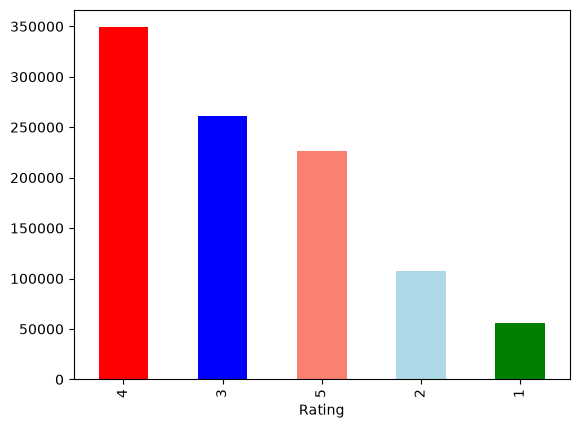

In [12]:
ratings["Rating"].value_counts().plot(kind="bar", color=["red", "blue", "salmon", "lightblue", "green"]);

In [13]:
ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   UserID     1000209 non-null  int64
 1   MovieID    1000209 non-null  int64
 2   Rating     1000209 non-null  int64
 3   Timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB


In [14]:
# Are there any missing values?
ratings.isna().sum()

UserID       0
MovieID      0
Rating       0
Timestamp    0
dtype: int64

In [15]:
ratings.describe()

,UserID,MovieID,Rating,Timestamp
count,1.000209e+06,1.000209e+06,1.000209e+06,1.000209e+06
mean,3.024512e+03,1.865540e+03,3.581564e+00,9.722437e+08
std,1.728413e+03,1.096041e+03,1.117102e+00,1.215256e+07
min,1.000000e+00,1.000000e+00,1.000000e+00,9.567039e+08
25%,1.506000e+03,1.030000e+03,3.000000e+00,9.653026e+08
50%,3.070000e+03,1.835000e+03,4.000000e+00,9.730180e+08
75%,4.476000e+03,2.770000e+03,4.000000e+00,9.752209e+08
max,6.040000e+03,3.952000e+03,5.000000e+00,1.046455e+09


### Movies dataset

In [16]:
movies.head()

,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [17]:
movies.shape

(3883, 3)

In [18]:
movies["MovieID"].value_counts()

MovieID
1       1
2       1
3       1
4       1
5       1
       ..
3948    1
3949    1
3950    1
3951    1
3952    1
Name: count, Length: 3883, dtype: int64

In [19]:
movies["Title"].value_counts()

Title
Toy Story (1995)                      1
Jumanji (1995)                        1
Grumpier Old Men (1995)               1
Waiting to Exhale (1995)              1
Father of the Bride Part II (1995)    1
                                     ..
Meet the Parents (2000)               1
Requiem for a Dream (2000)            1
Tigerland (2000)                      1
Two Family House (2000)               1
Contender, The (2000)                 1
Name: count, Length: 3883, dtype: int64

In [20]:
movies["Genres"].value_counts()

Genres
Drama                              843
Comedy                             521
Horror                             178
Comedy|Drama                       162
Comedy|Romance                     142
                                  ... 
Drama|Film-Noir                      1
Comedy|Horror|Sci-Fi                 1
Adventure|Drama|Romance|Sci-Fi       1
Adventure|Animation|Sci-Fi           1
Adventure|Crime|Sci-Fi|Thriller      1
Name: count, Length: 301, dtype: int64

In [21]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   MovieID  3883 non-null   int64
 1   Title    3883 non-null   str  
 2   Genres   3883 non-null   str  
dtypes: int64(1), str(2)
memory usage: 91.1 KB


In [22]:
# Are there any missing values?
movies.isna().sum()

MovieID    0
Title      0
Genres     0
dtype: int64

In [23]:
movies.describe()

,MovieID
count,3883.000000
mean,1986.049446
std,1146.778349
min,1.000000
25%,982.500000
50%,2010.000000
75%,2980.500000
max,3952.000000


### Tabular View

In [24]:
def tabular_preview(ratings, n=15):
    """Creates a cross-tabular view of users vs movies"""
    user_groups = ratings.groupby("UserID")["Rating"].count()
    top_users = user_groups.sort_values(ascending=False)[:n]

    movie_groups = ratings.groupby("MovieID")["Rating"].count()
    top_movies = movie_groups.sort_values(ascending=False)[:n]

    top = (
        ratings.
        join(top_users, lsuffix="_l", rsuffix="_r", how="inner", on="UserID").
        join(top_movies, lsuffix="_l", rsuffix="_r", how="inner", on="MovieID")
    )
    return pd.crosstab(top.UserID, top.MovieID, top.Rating_l, aggfunc=sum)

In [25]:
tabular_preview(ratings, 15)

MovieID,110,260,480,589,593,608,1196,1198,1210,1270,1580,2028,2571,2762,2858
UserID,,,,,,,,,,,,,,,
889,4.0,4.0,3.0,5.0,5.0,4.0,4.0,NaN,3.0,4.0,3.0,3.0,5.0,NaN,2.0
1015,4.0,5.0,4.0,5.0,5.0,5.0,4.0,5.0,4.0,4.0,4.0,5.0,5.0,5.0,4.0
1150,2.0,5.0,NaN,2.0,3.0,5.0,4.0,2.0,3.0,2.0,2.0,2.0,1.0,2.0,4.0
1181,3.0,4.0,2.0,5.0,3.0,3.0,4.0,3.0,3.0,3.0,4.0,4.0,5.0,4.0,3.0
1449,3.0,3.0,2.0,2.0,5.0,5.0,3.0,4.0,2.0,2.0,4.0,3.0,4.0,4.0,4.0
1680,1.0,2.0,5.0,5.0,5.0,5.0,5.0,5.0,3.0,3.0,4.0,5.0,3.0,5.0,5.0
1941,5.0,5.0,5.0,3.0,5.0,4.0,5.0,5.0,5.0,5.0,5.0,5.0,3.0,5.0,1.0
1980,4.0,4.0,4.0,4.0,5.0,5.0,4.0,5.0,4.0,5.0,4.0,5.0,5.0,5.0,5.0
2063,5.0,4.0,4.0,2.0,5.0,2.0,4.0,4.0,4.0,4.0,3.0,2.0,5.0,4.0,5.0


# Data Preparation

In [26]:
# Split data into X and y
X = ratings.drop(["Rating", "Timestamp"], axis=1)
y = ratings["Rating"]

In [27]:
num_users, num_movies = X["UserID"].nunique(), X["MovieID"].nunique()
num_users, num_movies

(6040, 3706)

In [28]:
# Split data into train and val sets
np.random.seed(42)
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2)

In [29]:
# Create datasets
datasets = {"train": (X_train, y_train), "valid":(X_valid, y_valid)}
datasets_sizes = {"train": len(X_train), "valid":len(X_valid)}

In [30]:
datasets

{'train': (        UserID  MovieID
  416292    2507     3035
  683230    4087     2840
  2434        19      457
  688533    4118     2804
  472584    2907      805
  ...        ...      ...
  259178    1586     1077
  365838    2129     2700
  131932     854     3102
  671155    4033     3479
  121958     786     1391
  
  [800167 rows x 2 columns],
  416292    2
  683230    4
  2434      3
  688533    4
  472584    4
           ..
  259178    5
  365838    5
  131932    3
  671155    5
  121958    4
  Name: Rating, Length: 800167, dtype: int64),
 'valid': (        UserID  MovieID
  895536    5412     2683
  899739    5440      904
  55687      368     3717
  63727      425     1721
  822011    4942     3697
  ...        ...      ...
  756007    4505     1396
  477775    2934      724
  424188    2572      968
  293600    1748     1625
  149989     965     1233
  
  [200042 rows x 2 columns],
  895536    2
  899739    5
  55687     4
  63727     4
  822011    1
           ..
  756007 

In [31]:
datasets_sizes

{'train': 800167, 'valid': 200042}

In [32]:
min_max = (ratings.Rating.min(), ratings.Rating.max())
min_max

(np.int64(1), np.int64(5))

# Embeddings

We will create an nn.Module for our embedding network
* It will create a network of arbitrary depth, with or without dropouts
* `forward` method accepts and additional `min_max` argument. It will be a tuple with min and max values of ratings from the dataset to normalize the predicated value into a specific range.
* We use a generator function `gen_layers` that yields linear and dropout layers depending on values from `hidden` and `dropouts` arrays.
* We use the `nn.Sequence` class to group hidden layers into a single module

In [33]:
class EmbeddingNet(nn.Module):
    """
    Creates a dense network with embedding layers.

    Args:
        num_users: 
            Number of unique users in the dataset.
        num_movies: 
            Number of unique movies in the dataset.
        num_factors: 
            Number of columns in the embeddings matrix.
        embedding_dropout: 
            Dropout rate to apply right after embeddings layer.
        hidden: 
            A single integer or a list of integers defining the number of 
            units in hidden layer(s).
        dropouts: 
            A single integer or a list of intergers defining the dropout 
            layers rates applied right after each of the hidden layers.
    """
    def __init__(self, num_users, num_movies, num_factors=50, embedding_dropout=0.02, hidden=10, dropouts=0.2):
        super().__init__()
        hidden = self.get_list(hidden)
        dropouts = self.get_list(dropouts)
        n_last = hidden[-1]

        def gen_layers(n_in):
            """
            A generator that yields a sequence of hidden layers and
            their activations/dropouts.
    
            Note that the function captures "hidden" and "dropouts"
            values from the outer scope
            """
            nonlocal hidden, dropouts
            assert len(dropouts) <= len(hidden)
    
            for n_out, rate in zip_longest(hidden, dropouts):
                yield nn.Linear(n_in, n_out)
                yield nn.ReLU()
                if rate is not None and rate > 0.:
                    yield nn.Dropout(rate)
                n_in = n_out
    
        self.users = nn.Embedding(num_users, num_factors)
        self.movies = nn.Embedding(num_movies, num_factors) 
        self.drop = nn.Dropout(embedding_dropout)
        self.hidden = nn.Sequential(*list(gen_layers(num_factors * 2)))
        self.fc = nn.Linear(n_last, 1)
        self._init()

    def _init(self):
        """
        Setup embeddings and hidden layers with reasonable initial values
        """
        def init(m):
            if type(m) == nn.Linear:
                torch.nn.init.xavier_uniform_(m.weight)
                m.bias.data.fill_(0.01)
        self.users.weight.data.uniform_(-0.05, 0.05)
        self.movies.weight.data.uniform_(-0.05,0.05)
        self.hidden.apply(init)
        init(self.fc)
    
    def forward(self, users, movies, min_max=None):
        features = torch.cat((self.users(users), self.movies(movies)), dim=1)
        X = self.drop(features)
        X = self.hidden(X)
        out = torch.sigmoid(self.fc(X))
        if min_max is not None:
            min_rating, max_rating = min_max
            out = out * (max_rating - min_rating + 1) + min_rating - 0.5
        return out

    def get_list(self, n):
        if isinstance(n, (int, float)):
            return [n]
        elif isinstance(n, list):
            return n
        raise TypeError("Layers configuration should be a single number or a list of numbers")

In [34]:
# Create object of class EmbeddingNet
net = EmbeddingNet(num_users = num_users,
                   num_movies = num_movies,
                   num_factors=150,
                   hidden=[500, 500, 500],
                   embedding_dropout=0.1,
                   dropouts=[0.2, 0.4])

# Cyclical Learning Rate (CLR)

The `CyclicLR` class expectates a single callback funtion. It will accept the current training epoch and the base value of the learning rate, and return a new learning rate value
* The `get_lr()` method is invoked each time we call the `step()` method. It returns a list of learning rates depending on the current training epoch. In our case, we have the same learning rate for all layers so we will return a list with a single value.


In [35]:
class CyclicLR(_LRScheduler):
    def __init__(self, optimizer, schedule, last_epoch=-1):
        assert callable(schedule)
        self.schedule = schedule
        super().__init__(optimizer, last_epoch)

    def get_lr(self):
        return [self.schedule(self.last_epoch, lr) for lr in self.base_lrs]

# Cosine annealing scheduler
* It starts with `base_lr` and grdually decreases it

In [36]:
def cosine(t_max, eta_min=0):
    def scheduler(epoch, base_lr):
        t = epoch % t_max
        return eta_min + (base_lr - eta_min)*(1 + math.cos(math.pi*t/t_max))/2
    return scheduler

# Determine which device to use

In [37]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("🚀 Success! PyTorch is utilizing your MacBook Air M5 GPU.")
elif torch.backends.mps.is_built():
    device = torch.device("cpu")
    print("⚠️ MPS is compiled but not available. Falling back to CPU.")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    print("🚀 Success! PyTorch is utilizing your Nvidia GPU.")
elif torch.backends.cuda.is_built():
    device = torch.device("cpu")
    print("⚠️ CUDA is compiled but not available. Falling back to CPU.")
else:
    device = torch.device("cpu")
    print("❌ MPS backend not found in this PyTorch build. Using CPU.")

🚀 Success! PyTorch is utilizing your MacBook Air M5 GPU.


# Prepare and run the training loop 
* It will have cyclical learning rate, validation and early stopping
* We use `Adam` optimizer with cosine-annealing learning rate.
    * The rate is decreased on each batch during `2` epochs, and then is reset to the original value
* Loop has two phases:
    * `Train` - During this phase,we update our network's weights and change the learning rate
    * `Valid` - Used to check the model's performance
* When the loss value decreases, we save model parameters to restore them later.
* If there is no improvement after 10 sequential training epochs, we exit the loop.

In [38]:
# Reviews Iterator function - Iterate through dataset, one batch after another
class ReviewsIterator:
    def __init__(self, X, y, batch_size=32):
        X, y = np.asarray(X), np.asarray(y)
        index = np.random.permutation(X.shape[0])
        X, y = X[index], y[index]
        self.X = X
        self.y = y
        self.batch_size = batch_size
        self.n_batches = int(math.ceil(X.shape[0] // batch_size))
        self.current = 0

    # Makes class iterable
    def __iter__(self):
        return self

    # Retrives next element from the iterator
    def __next__(self):
        return self.next()

    def next(self):
        if self.current >= self.n_batches:
            raise StopIteration()
        left = self.current * self.batch_size
        self.current += 1
        right = self.current * self.batch_size
        return self.X[left:right], self.y[left:right]

    def __str__(self):
        return f"X={self.X}, y={self.y}, batch_size={self.batch_size}, n_batches={self.n_batches}, current={self.current}"

In [39]:
# Batches Function
def batches(X, y, batch_size=32):
    for xb, yb in ReviewsIterator(X, y, batch_size):
        xb = torch.LongTensor(xb)
        yb = torch.FloatTensor(yb)
        yield xb, yb.view(-1, 1)

In [40]:
learn_rate = 1e-3
weight_decay = 1e-5
batch_size = 2000
num_epochs = 100
patience = 10
no_improvements = 0
best_loss = np.inf
best_weights = None
history = []
lr_history = []

net.to(device)
criterion = nn.MSELoss(reduction="sum")
optimizer = optim.Adam(net.parameters(), lr=learn_rate, weight_decay=weight_decay)
iterations_per_epoch = int(math.ceil(datasets_sizes["train"] // batch_size))
scheduler = CyclicLR(optimizer, cosine(t_max=iterations_per_epoch * 2, eta_min=learn_rate/10))

for epoch in range(num_epochs):
    stats = {"epochs": epoch+1, "total": num_epochs}
    for phase in ("train", "valid"):
        training = phase == "train"
        running_loss = 0.0
        n_batches = 0
        for batch in batches(datasets[phase][0], datasets[phase][1], batch_size=batch_size):
            X_batch, y_batch = [b.to(device) for b in batch]
            optimizer.zero_grad()
            # Compute gradients only during "train" phase
            with torch.set_grad_enabled(training):
                outputs = net(X_batch[:, 0], X_batch[:, 1], min_max)
                loss = criterion(outputs, y_batch)
                # don't update weights and rates when in "validate" phase
                if training:
                    scheduler.step()
                    loss.backward()
                    optimizer.step()
                    lr_history.extend(scheduler.get_lr())
            running_loss += loss.item()
        epoch_loss = running_loss / datasets_sizes[phase]
        stats[phase] = epoch_loss
        # early stopping: save weights of the best model so far
        if phase == "valid":
            if epoch_loss < best_loss:
                print(f"Loss improvement on epoch {epoch+1}")
                best_loss = epoch_loss
                best_weights = copy.deepcopy(net.state_dict())
                no_improvements = 0
            else:
                no_improvements += 1
    history.append(stats)
    print(f"[{epoch+1}/{num_epochs}], train: {history[epoch]["train"]} - val: {history[epoch]["train"]}")
        
    if no_improvements >= patience:
        print(f"early stopping after epoch {stats["epochs"]}")
        break

/var/folders/z1/xrwht_kd0r54n8qj8_jdt1080000gn/T/ipykernel_34317/1957586751.py:33: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Loss improvement on epoch 1
[1/100], train: 0.8842264635631335 - val: 0.8842264635631335
Loss improvement on epoch 2
[2/100], train: 0.7999446154128509 - val: 0.7999446154128509
Loss improvement on epoch 3
[3/100], train: 0.8007945327496869 - val: 0.8007945327496869
Loss improvement on epoch 4
[4/100], train: 0.7574908094929812 - val: 0.7574908094929812
[5/100], train: 0.7670049191562316 - val: 0.7670049191562316
[6/100], train: 0.7257181117518866 - val: 0.7257181117518866
Loss improvement on epoch 7
[7/100], train: 0.7359934289376272 - val: 0.7359934289376272
[8/100], train: 0.6718381285770365 - val: 0.6718381285770365
[9/100], train: 0.6839040431974864 - val: 0.6839040431974864
[10/100], train: 0.6079762177465279 - val: 0.6079762177465279
[11/100], train: 0.6285105553948279 - val: 0.6285105553948279
[12/100], train: 0.5567387081628351 - val: 0.5567387081628351
[13/100], train: 0.5826469373627142 - val: 0.5826469373627142
[14/100], train: 0.5197898260118815 - val: 0.5197898260118815
[

# Metrics

In [41]:
net.load_state_dict(best_weights)

<All keys matched successfully>

In [42]:
groud_truth, predictions = [], []
with torch.no_grad():
    for batch in batches(datasets["valid"][0], datasets["valid"][1], batch_size=batch_size):
        X_batch, y_batch = [b.to(device) for b in batch]
        outputs = net(X_batch[:, 0], X_batch[:, 1], min_max)
        groud_truth.extend(y_batch.tolist())
        predictions.extend(outputs.tolist())
groud_truth = np.asarray(groud_truth).ravel()
predictions = np.asarray(predictions).ravel()

In [43]:
final_loss = np.sqrt(np.mean((predictions - groud_truth)**2))
print(f"Final RMSE: {final_loss:.4f}")

Final RMSE: 0.8912


In [44]:
with open('best.weights', 'wb') as file:
    pickle.dump(best_weights, file)